In [1]:
# ------------------------------------------------------------
# Load the SAME inputs Step 2 saved, so every step uses identical numbers
# ------------------------------------------------------------
import json
import numpy as np
import pandas as pd

inputs = pd.read_csv("../outputs/inputs.csv", index_col="name")
with open("../outputs/settings.json") as f:
    S = json.load(f)

# p = a simple dictionary {parameter name: base value}, e.g. p["p_stroke"] = 0.016
p = inputs["base"].to_dict()

dt = S["cycle_years"]          # 0.25 years = one 3-month cycle

print("Parameters loaded:", len(p))
print("Apixaban annual cost:", round(p["c_apixaban"], 2))
print("Cycle length (years):", dt)

Parameters loaded: 50
Apixaban annual cost: 298.34
Cycle length (years): 0.25


In [2]:
# ------------------------------------------------------------
# PROBLEM: inputs are ANNUAL probabilities (1.6% have a stroke per year),
# but the model runs in 3-month cycles. You can't just divide by 4.
# Probabilities don't add up over time; RATES do.
#
#   annual probability --> rate --> 3-month probability
# ------------------------------------------------------------

def to_rate(prob):
    """Annual probability -> annual instantaneous rate.   r = -ln(1 - p)"""
    return -np.log(1 - prob)

def to_cycle_prob(rate, dt=0.25):
    """Rate -> probability of the event within one cycle.   p = 1 - exp(-r * dt)"""
    return 1 - np.exp(-rate * dt)

def apply_odds_ratio(prob, odds_ratio):
    """
    Apply an odds ratio to a probability.
    Convert to odds, multiply by the OR, convert back:
        p_new = OR * p / (1 - p + OR * p)
    (Multiplying a probability directly by an OR is a classic error
    that reviewers look for.)
    """
    return odds_ratio * prob / (1 - prob + odds_ratio * prob)

# --- Demonstration: stroke risk on warfarin
r = to_rate(p["p_stroke"])
p3 = to_cycle_prob(r, dt)
print(f"Annual stroke probability : {p['p_stroke']:.4f}")
print(f"Annual stroke rate        : {r:.6f}")
print(f"3-month probability       : {p3:.6f}")
print(f"(naive divide-by-4 gives  : {p['p_stroke']/4:.6f})")

# --- How much apixaban reduces each event in a 3-month cycle
print("\nEvent        Warfarin    Apixaban")
for event, or_name in [("p_stroke", "or_apx_stroke"), ("p_ich", "or_apx_ich"),
                       ("p_major_bleed", "or_apx_mb"), ("p_mi", "or_apx_mi")]:
    warf = to_cycle_prob(to_rate(p[event]), dt)
    apx = apply_odds_ratio(warf, p[or_name])
    print(f"{event:13s} {warf:.6f}    {apx:.6f}")

Annual stroke probability : 0.0160
Annual stroke rate        : 0.016129
3-month probability       : 0.004024
(naive divide-by-4 gives  : 0.004000)

Event        Warfarin    Apixaban
p_stroke      0.004024    0.003182
p_ich         0.002006    0.000844
p_major_bleed 0.008354    0.006694
p_mi          0.001503    0.001323


In [3]:
# ------------------------------------------------------------
# One 3-month cycle for 1 patient who starts in S0 (AF, no event), age 70.
# Order of operations:
#   1. Some die of background (non-stroke) causes
#   2. Survivors may have ONE event: stroke, ICH, major bleed, MI, TIA, minor bleed
#   3. Each event is split into fatal / non-fatal and routed to a new state
# ------------------------------------------------------------

def one_cycle_from_S0(arm):
    # 1. Background death (age 70, so no age adjustment yet)
    p_death = to_cycle_prob(to_rate(p["p_nonvasc_death"]), dt)
    alive = 1 - p_death

    # 2. Event probabilities this cycle (warfarin baseline)
    prob = {
        "stroke": to_cycle_prob(to_rate(p["p_stroke"]), dt),
        "ich":    to_cycle_prob(to_rate(p["p_ich"]), dt),
        "mb":     to_cycle_prob(to_rate(p["p_major_bleed"]), dt),
        "mi":     to_cycle_prob(to_rate(p["p_mi"]), dt),
    }
    # Apixaban arm: apply the odds ratios
    if arm == "apixaban":
        prob["stroke"] = apply_odds_ratio(prob["stroke"], p["or_apx_stroke"])
        prob["ich"]    = apply_odds_ratio(prob["ich"],    p["or_apx_ich"])
        prob["mb"]     = apply_odds_ratio(prob["mb"],     p["or_apx_mb"])
        prob["mi"]     = apply_odds_ratio(prob["mi"],     p["or_apx_mi"])

    # Number of people having each event
    n = {k: alive * v for k, v in prob.items()}

    # 3. Route them
    fatal_stroke = n["stroke"] * p["f_stroke_fatal"]
    major_stroke = n["stroke"] * (1 - p["f_stroke_fatal"]) * p["f_stroke_major"]
    minor_stroke = n["stroke"] * (1 - p["f_stroke_fatal"]) * (1 - p["f_stroke_major"])
    ich_survive  = n["ich"] * (1 - p["f_bleed_fatal"])
    mb_survive   = n["mb"]  * (1 - p["f_bleed_fatal"])

    dead = (p_death + fatal_stroke
            + n["ich"] * p["f_bleed_fatal"]
            + n["mb"]  * p["f_bleed_fatal"]
            + n["mi"]  * p["f_mi_fatal"])
    S1 = minor_stroke + ich_survive        # minor stroke or survived ICH
    S2 = major_stroke
    S3 = mb_survive
    # Everyone else stays in S0 (TIA, minor bleed and survived MI cost
    # money and QALYs, but don't change the patient's state)
    S0 = 1 - dead - S1 - S2 - S3

    return pd.Series({"S0": S0, "S1": S1, "S2": S2, "S3": S3, "Dead": dead})

result = pd.DataFrame({"Warfarin": one_cycle_from_S0("warfarin"),
                       "Apixaban": one_cycle_from_S0("apixaban")})
print(result.round(6))
print("\nColumn sums (must be exactly 1):")
print(result.sum().round(10))

      Warfarin  Apixaban
S0    0.977201  0.980857
S1    0.003853  0.002372
S2    0.001014  0.000802
S3    0.007588  0.006081
Dead  0.010343  0.009889

Column sums (must be exactly 1):
Warfarin    1.0
Apixaban    1.0
dtype: float64


In [4]:
%%writefile markov_model.py
"""
markov_model.py
Cohort Markov model: generic apixaban vs warfarin in atrial fibrillation.

5 states, 3-month cycles, age 70 to 100, CADTH worked-example structure.
Every parameter can be a single number (deterministic run) or a NumPy array
of draws (probabilistic run, Step 6). The same code handles both.
"""
import json
import numpy as np
import pandas as pd

STATES = ["S0", "S1", "S2", "S3", "Dead"]
REF_AGE = 70          # age at which the trial-based rates apply


# --- conversion helpers (Step 3, part 1) -----------------------------
def to_rate(prob):
    return -np.log(1 - prob)

def to_cycle_prob(rate, dt):
    return 1 - np.exp(-rate * dt)

def apply_odds_ratio(prob, odds_ratio):
    return odds_ratio * prob / (1 - prob + odds_ratio * prob)


def load_inputs(folder="../outputs"):
    """Return (p, settings): base-case parameters and model settings."""
    inputs = pd.read_csv(f"{folder}/inputs.csv", index_col="name")
    with open(f"{folder}/settings.json") as f:
        settings = json.load(f)
    return inputs["base"].to_dict(), settings


def run_arm(p, arm, settings, keep_trace=False):
    """
    Run one treatment arm through the full lifetime horizon.

    p         dict of parameters (numbers or arrays)
    arm       "apixaban" or "warfarin"
    settings  dict from settings.json (can be edited for scenarios)
    Returns a dict of discounted and undiscounted totals.
    """
    dt = settings["cycle_years"]
    n_cycles = int(round((settings["max_age"] - settings["start_age"]) / dt))
    slope, intercept = settings["gompertz_slope"], settings["gompertz_intercept"]

    def qx_general(age):
        # Fitted StatCan mortality at a given age (Gompertz curve from Step 2)
        return np.minimum(np.exp(intercept + slope * age), 1.0)

    # Everyone starts in S0. Each state holds the FRACTION of the cohort in it.
    occ = {s: 0.0 for s in STATES}
    occ["S0"] = 1.0

    # Annual cost of the strategy while in S0: the ONLY drug difference
    if arm == "apixaban":
        cost_S0_drug = p["c_apixaban"]
    else:
        cost_S0_drug = p["c_warfarin"] + p["c_inr"]

    # Annual utility and long-term cost of each living state
    u_major = (1 - p["p_rankin_5"]) * p["u_rankin_3_4"] + p["p_rankin_5"] * p["u_rankin_5"]
    utility = {"S0": p["u_af"], "S1": p["u_minor_stroke"], "S2": u_major, "S3": p["u_af"]}
    lt_cost = {"S0": 0.0, "S1": p["c_lt_minor_stroke"], "S2": p["c_lt_major_stroke"], "S3": 0.0}

    # Running totals
    keys = ["cost", "cost_drug", "cost_event", "cost_lt", "qaly", "ly",
            "cost_undisc", "qaly_undisc", "ly_undisc", "strokes", "ich", "major_bleeds"]
    tot = {k: 0.0 for k in keys}
    trace, yearly_cost, year_acc = [], [], 0.0

    for t in range(n_cycles):
        age = settings["start_age"] + t * dt
        discount = (1 + settings["discount_rate"]) ** -(t * dt)

        # Background death: the trial's rate at 70, rising with age like
        # the general population (only the GRADIENT of the life table is used)
        q_bg = np.minimum(p["p_nonvasc_death"] * qx_general(np.floor(age))
                          / qx_general(REF_AGE), 0.999)

        if keep_trace:
            trace.append({"age": age, **{s: float(np.mean(occ[s])) for s in STATES}})

        new = {s: 0.0 for s in STATES}
        new["Dead"] = occ["Dead"]
        cycle_cost = 0.0

        for s in ["S0", "S1", "S2", "S3"]:
            prior_stroke = s in ("S1", "S2")        # stroke history raises risks
            on_aspirin = s != "S0"                  # anticoagulation stopped

            # 1. background death (higher after a stroke)
            hr = p["hr_death_prior_stroke"] if prior_stroke else 1.0
            p_death = to_cycle_prob(to_rate(q_bg) * hr, dt)
            alive = occ[s] * (1 - p_death)

            # 2. event RATES, adjusted for age, history and aspirin
            r = {
                "stroke": to_rate(p["p_stroke"]) * p["rr_stroke_per_decade"] ** ((age - REF_AGE) / 10),
                "ich":    to_rate(p["p_ich"]),
                "mb":     to_rate(p["p_major_bleed"]),
                "mi":     to_rate(p["p_mi"]),
                "tia":    to_rate(p["p_tia"]),
                "minor":  to_rate(p["p_minor_bleed"]),
            }
            if prior_stroke:
                r["stroke"] = r["stroke"] * p["rr_stroke_prior"]
            if on_aspirin:
                for ev, rr in [("stroke", "rr_asa_stroke"), ("ich", "rr_asa_ich"),
                               ("mb", "rr_asa_mb"), ("mi", "rr_asa_mi"),
                               ("tia", "rr_asa_tia"), ("minor", "rr_asa_minor")]:
                    r[ev] = r[ev] * p[rr]

            prob = {ev: to_cycle_prob(rate, dt) for ev, rate in r.items()}
            if arm == "apixaban" and s == "S0":
                for ev, orn in [("stroke", "or_apx_stroke"), ("ich", "or_apx_ich"),
                                ("mb", "or_apx_mb"), ("mi", "or_apx_mi")]:
                    prob[ev] = apply_odds_ratio(prob[ev], p[orn])

            n = {ev: alive * pr for ev, pr in prob.items()}

            # 3. route events
            f_stroke = np.minimum(p["f_stroke_fatal"] * (p["hr_recur_fatal"] if prior_stroke else 1.0), 1.0)
            stroke_dead  = n["stroke"] * f_stroke
            stroke_major = n["stroke"] * (1 - f_stroke) * p["f_stroke_major"]
            stroke_minor = n["stroke"] * (1 - f_stroke) * (1 - p["f_stroke_major"])
            ich_live = n["ich"] * (1 - p["f_bleed_fatal"])
            mb_live  = n["mb"] * (1 - p["f_bleed_fatal"])
            mi_dead  = n["mi"] * p["f_mi_fatal"]
            mi_live  = n["mi"] - mi_dead
            stay = alive - n["stroke"] - n["ich"] - n["mb"] - mi_dead

            new["Dead"] += (occ[s] * p_death + stroke_dead + (n["ich"] - ich_live)
                            + (n["mb"] - mb_live) + mi_dead)
            new["S2"] += stroke_major
            # minor stroke / ICH: to S1, unless already in S2 (stay there)
            new["S2" if s == "S2" else "S1"] += stroke_minor + ich_live
            # major bleed: S0 -> S3; already on aspirin -> stay put
            new["S3" if s == "S0" else s] += mb_live
            new[s] += stay

            # 4. costs: drug + long-term care on time in state, plus event costs
            c_drug = occ[s] * (cost_S0_drug if s == "S0" else p["c_aspirin"]) * dt
            c_lt = occ[s] * lt_cost[s] * dt
            c_evt = (stroke_dead * p["c_stroke_fatal"] + stroke_major * p["c_stroke_major"]
                     + stroke_minor * p["c_stroke_minor"] + n["ich"] * p["c_ich"]
                     + n["mb"] * p["c_major_bleed"] + mi_dead * p["c_mi_fatal"]
                     + mi_live * p["c_mi_nonfatal"] + n["tia"] * p["c_tia"]
                     + n["minor"] * p["c_minor_bleed"])

            # 5. QALYs: time in state x utility, minus one-off event losses
            u = utility[s] - p["dec_per_year_over_70"] * max(age - REF_AGE, 0)
            q = occ[s] * u * dt - dt * (mi_live * p["dec_mi"] + mb_live * p["dec_major_bleed"]
                                        + n["minor"] * p["dec_minor_bleed"] + n["tia"] * p["dec_tia"])

            # 6. add to totals (discounted and undiscounted)
            tot["cost"] += (c_drug + c_lt + c_evt) * discount
            tot["cost_drug"] += c_drug * discount
            tot["cost_event"] += c_evt * discount
            tot["cost_lt"] += c_lt * discount
            tot["qaly"] += q * discount
            tot["ly"] += occ[s] * dt * discount
            tot["cost_undisc"] += c_drug + c_lt + c_evt
            tot["qaly_undisc"] += q
            tot["ly_undisc"] += occ[s] * dt
            tot["strokes"] += n["stroke"]
            tot["ich"] += n["ich"]
            tot["major_bleeds"] += n["mb"]
            cycle_cost = cycle_cost + c_drug + c_lt + c_evt

        occ = new
        year_acc = year_acc + cycle_cost
        if (t + 1) % 4 == 0:                    # every 4 cycles = 1 year
            yearly_cost.append(year_acc)
            year_acc = 0.0

    tot["yearly_cost_undisc"] = yearly_cost     # used by the budget impact (Step 8)
    if keep_trace:
        tot["trace"] = pd.DataFrame(trace)
    return tot


def run_both(p, settings, **kw):
    """Run both arms with the same inputs. Returns (apixaban, warfarin)."""
    return run_arm(p, "apixaban", settings, **kw), run_arm(p, "warfarin", settings, **kw)

Writing markov_model.py


In [5]:
# ------------------------------------------------------------
# Import the model file and run the reference case
# ------------------------------------------------------------
import pandas as pd
from markov_model import load_inputs, run_both

p, S = load_inputs()
apx, war = run_both(p, S)

rows = {
    "Total cost (discounted)":  "cost",
    "  Drug + monitoring":      "cost_drug",
    "  Clinical events":        "cost_event",
    "  Long-term stroke care":  "cost_lt",
    "QALYs (discounted)":       "qaly",
    "Life-years (discounted)":  "ly",
    "Strokes per 1,000":        "strokes",
    "ICH per 1,000":            "ich",
    "Major bleeds per 1,000":   "major_bleeds",
}
def col(res):
    # event counts are per patient, so multiply by 1,000 for readability
    return {label: res[key] * (1000 if "per 1,000" in label else 1)
            for label, key in rows.items()}

results = pd.DataFrame({"Apixaban": col(apx), "Warfarin": col(war)})
results["Difference"] = results["Apixaban"] - results["Warfarin"]

pd.set_option("display.float_format", "{:,.3f}".format)
print(results)

                          Apixaban   Warfarin  Difference
Total cost (discounted) 22,807.847 28,415.756  -5,607.909
  Drug + monitoring      2,362.097  2,791.203    -429.106
  Clinical events       11,499.738 13,952.852  -2,453.114
  Long-term stroke care  8,946.012 11,671.701  -2,725.689
QALYs (discounted)           7.464      7.228       0.236
Life-years (discounted)      9.388      9.129       0.258
Strokes per 1,000          238.605    281.751     -43.145
ICH per 1,000               35.521     69.803     -34.283
Major bleeds per 1,000     292.375    338.930     -46.555


Mass balance, min and max: 1.0 1.0
      age    S0    S1    S2    S3  Dead
0  70.000 1.000 0.000 0.000 0.000 0.000
20 75.000 0.599 0.050 0.016 0.098 0.237
40 80.000 0.303 0.047 0.019 0.105 0.526
60 85.000 0.115 0.021 0.010 0.062 0.792
80 90.000 0.026 0.004 0.002 0.019 0.948


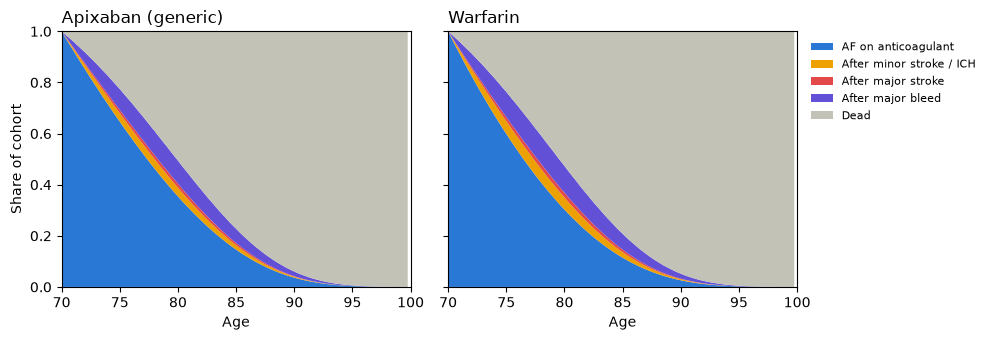

In [6]:
# ------------------------------------------------------------
# Where is the cohort at each age? Rows must always sum to 1.
# ------------------------------------------------------------
import matplotlib.pyplot as plt

apx_t, war_t = run_both(p, S, keep_trace=True)
trace = war_t["trace"]

# Mass-balance check across ALL 120 cycles
total = trace[["S0", "S1", "S2", "S3", "Dead"]].sum(axis=1)
print("Mass balance, min and max:", round(total.min(), 10), round(total.max(), 10))

# Snapshot every 5 years (every 20 cycles), warfarin arm
print(trace.iloc[[0, 20, 40, 60, 80]].round(4))

# Stacked area chart, both arms side by side
labels = ["AF on anticoagulant", "After minor stroke / ICH",
          "After major stroke", "After major bleed", "Dead"]
colours = ["#2a78d6", "#eda100", "#e34948", "#6250d6", "#c3c2b7"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, res, title in [(axes[0], apx_t, "Apixaban (generic)"), (axes[1], war_t, "Warfarin")]:
    tr = res["trace"]
    ax.stackplot(tr["age"], tr[["S0", "S1", "S2", "S3", "Dead"]].T,
                 labels=labels, colors=colours)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Age"); ax.set_xlim(70, 100); ax.set_ylim(0, 1)
axes[0].set_ylabel("Share of cohort")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig("../outputs/fig_markov_trace.png", dpi=150, bbox_inches="tight")
plt.show()